<a href="https://colab.research.google.com/github/Khalidgh707/Machine-Learning-Project/blob/main/DS471ML_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# DS-471 Machine Learning Project: Energy Efficiency Prediction
**Dataset:** UCI Energy Efficiency (ENB2012) | **Problem:** Regression (predict the **Heating Load, Y1** of a building)

**Group members:**
*   Khalid A ALghamdi #210038421
*   Fahad Alkhamees #220033879
*   Abdullah S Almutairi#230031752

**Course:** DS471

**CRN**: 10700


**Deadline:** 30/11/2026

**Workflow:** by stage
1.   Data preparation and EDA
2.   Splitting
3.   Model selection
4.   Training and tuning
5.   Final evaluation and comparison


## Stage 1: Data Cleaning, Preparation and Exploration
### 1.0 Setup

In [1]:
import os, random, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
warnings.filterwarnings("ignore")

SEED = 42
random.seed(SEED); np.random.seed(SEED)

os.makedirs("figures", exist_ok=True)   # all figures for the report are saved here
os.makedirs("results", exist_ok=True)
sns.set_style("whitegrid")

### 1.1 Load the data

In [5]:
DATA_FILE = "ENB2012_data.xlsx"
DATA_URL = None

if os.path.exists(DATA_FILE):
    df = pd.read_excel(DATA_FILE)
elif DATA_URL:
    df = pd.read_excel(DATA_URL)
else:
    from google.colab import files
    uploaded = files.upload()               # choose ENB2012_data.xlsx
    df = pd.read_excel(list(uploaded.keys())[0])

# Giving the columns meaningful names like on xlsx (X1..X8 = inputs, Y1, Y2 = outputs)
df = df.rename(columns={
    "X1": "relative_compactness", "X2": "surface_area", "X3": "wall_area", "X4": "roof_area",
    "X5": "overall_height", "X6": "orientation", "X7": "glazing_area",
    "X8": "glazing_area_distribution", "Y1": "heating_load", "Y2": "cooling_load"})
df.head()

,relative_compactness,surface_area,wall_area,roof_area,overall_height,orientation,glazing_area,glazing_area_distribution,heating_load,cooling_load
0,0.98,514.5,294.0,110.25,7.0,2,0.0,0,15.55,21.33
1,0.98,514.5,294.0,110.25,7.0,3,0.0,0,15.55,21.33
2,0.98,514.5,294.0,110.25,7.0,4,0.0,0,15.55,21.33
3,0.98,514.5,294.0,110.25,7.0,5,0.0,0,15.55,21.33
4,0.90,563.5,318.5,122.50,7.0,2,0.0,0,20.84,28.28


### 1.2 Understand the dataset (size, types, statistics)


In [6]:
print("Shape (rows, columns):", df.shape)
print()
df.info()
display(df.describe().T.round(3))
print("\nNumber of unique values per column:")
print(df.nunique())

Shape (rows, columns): (768, 10)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 10 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   relative_compactness       768 non-null    float64
 1   surface_area               768 non-null    float64
 2   wall_area                  768 non-null    float64
 3   roof_area                  768 non-null    float64
 4   overall_height             768 non-null    float64
 5   orientation                768 non-null    int64  
 6   glazing_area               768 non-null    float64
 7   glazing_area_distribution  768 non-null    int64  
 8   heating_load               768 non-null    float64
 9   cooling_load               768 non-null    float64
dtypes: float64(8), int64(2)
memory usage: 60.1 KB


,count,mean,std,min,25%,50%,75%,max
relative_compactness,768.0,0.764,0.106,0.62,0.682,0.75,0.830,0.98
surface_area,768.0,671.708,88.086,514.50,606.375,673.75,741.125,808.50
wall_area,768.0,318.500,43.626,245.00,294.000,318.50,343.000,416.50
roof_area,768.0,176.604,45.166,110.25,140.875,183.75,220.500,220.50
overall_height,768.0,5.250,1.751,3.50,3.500,5.25,7.000,7.00
orientation,768.0,3.500,1.119,2.00,2.750,3.50,4.250,5.00
glazing_area,768.0,0.234,0.133,0.00,0.100,0.25,0.400,0.40
glazing_area_distribution,768.0,2.812,1.551,0.00,1.750,3.00,4.000,5.00
heating_load,768.0,22.307,10.090,6.01,12.992,18.95,31.668,43.10
cooling_load,768.0,24.588,9.513,10.90,15.620,22.08,33.132,48.03



Number of unique values per column:
relative_compactness          12
surface_area                  12
wall_area                      7
roof_area                      4
overall_height                 2
orientation                    4
glazing_area                   4
glazing_area_distribution      6
heating_load                 587
cooling_load                 636
dtype: int64


Each row is one simulated building.

 The 8 inputs describe the shape and glazing of the building and the 2 outputs are the energy loads.

 We choose **heating_load (Y1)** as the target because the project needs one target variable. **cooling_load (Y2)** is another output (correlation with Y1 is about 0.98), so it must not be used as an input. orientation (2 to 5) and glazing_area_distribution (0 to 5) are codes of categories, not real quantities.

### 1.3 Missing values, duplicates and inconsistent data

In [7]:
print("Missing values per column:\n", df.isna().sum())
print("\nTotal missing values:", df.isna().sum().sum())
print("Duplicated rows:", df.duplicated().sum())
print("\nColumn types:\n", df.dtypes)
print("\nUnique values of the code columns:")
print("orientation:", sorted(df['orientation'].unique()))
print("glazing_area_distribution:", sorted(df['glazing_area_distribution'].unique()))
print("glazing_area:", sorted(df['glazing_area'].unique()))
# consistency: glazing area 0 should go with distribution 0 (no windows)
print("\nglazing_area = 0 rows and their distribution values:",
      df.loc[df.glazing_area == 0, 'glazing_area_distribution'].unique())

Missing values per column:
 relative_compactness         0
surface_area                 0
wall_area                    0
roof_area                    0
overall_height               0
orientation                  0
glazing_area                 0
glazing_area_distribution    0
heating_load                 0
cooling_load                 0
dtype: int64

Total missing values: 0
Duplicated rows: 0

Column types:
 relative_compactness         float64
surface_area                 float64
wall_area                    float64
roof_area                    float64
overall_height               float64
orientation                    int64
glazing_area                 float64
glazing_area_distribution      int64
heating_load                 float64
cooling_load                 float64
dtype: object

Unique values of the code columns:
orientation: [np.int64(2), np.int64(3), np.int64(4), np.int64(5)]
glazing_area_distribution: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5

### 1.4 Target variable

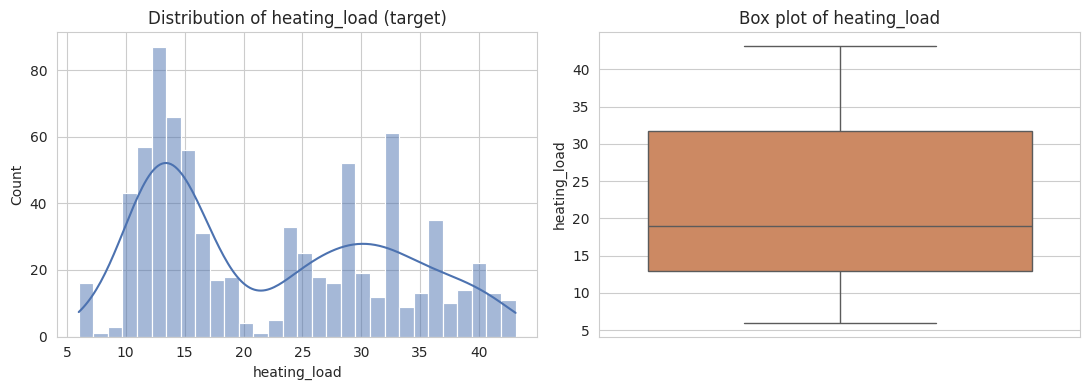

count    768.000
mean      22.307
std       10.090
min        6.010
25%       12.992
50%       18.950
75%       31.668
max       43.100
Name: heating_load, dtype: float64
Skewness: 0.36


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(df["heating_load"], bins=30, kde=True, ax=axes[0], color="#4C72B0")
axes[0].set_title("Distribution of heating_load (target)")
sns.boxplot(y=df["heating_load"], ax=axes[1], color="#DD8452")
axes[1].set_title("Box plot of heating_load")
plt.tight_layout(); plt.savefig("figures/fig1_target_distribution.png", dpi=200); plt.show()

print(df["heating_load"].describe().round(3))
print("Skewness:", round(df['heating_load'].skew(), 3))

The target is a **continuous number**, so this is a **regression** problem. Look at the histogram: if it has two groups (low-load and high-load buildings), explain it in the report. Metrics for regression are MAE, MSE, RMSE and R²

### 1.5 Outliers (**IQR rule**)

,feature,lower_limit,upper_limit,n_outliers
0,relative_compactness,0.461,1.051,0
1,surface_area,404.250,943.250,0
2,wall_area,220.500,416.500,0
3,roof_area,21.438,339.938,0
4,overall_height,-1.750,12.250,0
5,glazing_area,-0.350,0.850,0
6,heating_load,-15.020,59.680,0


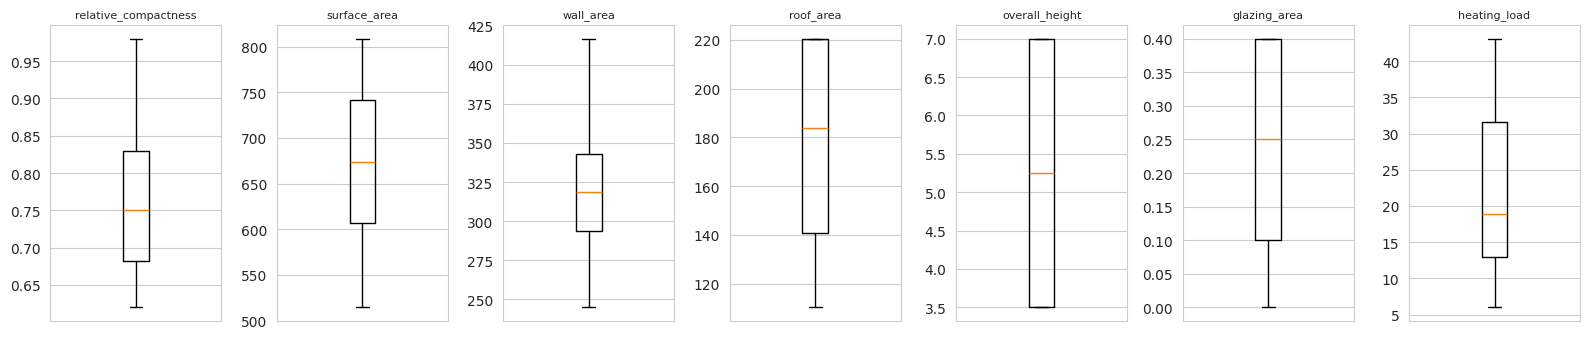

In [9]:
num_cols = ["relative_compactness", "surface_area", "wall_area", "roof_area",
            "overall_height", "glazing_area", "heating_load"]
rows = []
for c in num_cols:
    q1, q3 = df[c].quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    rows.append([c, round(low, 3), round(high, 3), int(((df[c] < low) | (df[c] > high)).sum())])
outliers = pd.DataFrame(rows, columns=["feature", "lower_limit", "upper_limit", "n_outliers"])
display(outliers)

fig, axes = plt.subplots(1, len(num_cols), figsize=(16, 3.5))
for ax, c in zip(axes, num_cols):
    ax.boxplot(df[c]); ax.set_title(c, fontsize=8); ax.set_xticks([])
plt.tight_layout(); plt.savefig("figures/fig2_boxplots.png", dpi=200); plt.show()